# Concurso público contracts

Contracts whose `tipo_procedimento` is a Concurso público variant: `Concurso público` (266 980) and `Concurso público simplificado` (137).

**Rule:** `tipo_procedimento` lowercased and accent-folded `.str.starts_with("concurso publico")`; `Concurso limitado…` and `Concurso de conceção…` are excluded. Reference: **267,117 rows** on the current parquet.

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import polars as pl

from base_gov.contracts import load_contracts
from base_gov.entities import (
    canonical_names,
    entity_key,
    explode_entities,
)
from base_gov.stats import MIN_VALUE, value_impact

DATA = Path("..") / "data"
pl.Config.set_tbl_rows(20)
pl.Config.set_tbl_width_chars(140)
plt.rcParams["figure.figsize"] = (10, 4)

In [2]:
contracts_all = load_contracts(DATA / "contracts.parquet")
print(f"rows={contracts_all.height:,}  cols={contracts_all.width}")
# Disregard contracts flagged is_below_min_value (|preco_contratual| < MIN_VALUE, €); contracts_all keeps them for before/after comparisons.
contracts = contracts_all.filter(~pl.col("is_below_min_value"))
print(f"disregarded {contracts_all.height - contracts.height:,} contracts with |preco_contratual| < €{MIN_VALUE:g} "
      f"({(contracts_all.height - contracts.height) / contracts_all.height:.2%}); kept {contracts.height:,}")
print(f"valor_por_dia defined for {contracts['valor_por_dia'].is_not_null().mean():.1%} of kept contracts "
      f"(needs 1 <= prazo_execucao <= 3650 days)")
contracts.head()
print(contracts["adjudicante_key_source"].value_counts(sort=True))

rows=2,295,074  cols=30
disregarded 12,658 contracts with |preco_contratual| < €10 (0.55%); kept 2,282,416
valor_por_dia defined for 97.9% of kept contracts (needs 1 <= prazo_execucao <= 3650 days)
shape: (2, 2)
┌────────────────────────┬─────────┐
│ adjudicante_key_source ┆ count   │
│ ---                    ┆ ---     │
│ str                    ┆ u32     │
╞════════════════════════╪═════════╡
│ nipc                   ┆ 2282390 │
│ name                   ┆ 26      │
└────────────────────────┴─────────┘


In [3]:
CP_EXPR = (
    pl.col("tipo_procedimento")
    .str.to_lowercase()
    .str.replace_all("ú", "u")
    .str.replace_all("é", "e")
    .str.starts_with("concurso publico")
)
contracts["tipo_procedimento"].value_counts(sort=True)

tipo_procedimento,count
str,u32
"""Ajuste Direto Regime Geral""",1316104
"""Consulta Prévia""",331977
"""Concurso público""",266980
"""Ao abrigo de acordo-quadro (ar…",225281
"""Ao abrigo de acordo-quadro (ar…",49652
"""Contratação excluída II""",40152
"""Ajuste direto simplificado""",37935
"""Concurso limitado por prévia q…",4381
"""Setores especiais – isenção pa…",3937


In [4]:
proc = contracts.filter(CP_EXPR)
print(f"Concurso público rows: {proc.height:,}  share by count: {proc.height / contracts.height:.1%}  "
      f"share by value: {proc['preco_contratual'].sum() / contracts['preco_contratual'].sum():.1%}")
variants = proc["tipo_procedimento"].value_counts(sort=True)
display(variants)
assert variants["count"].sum() == proc.height and proc.height < contracts.height
variants

n_before = contracts_all.filter(CP_EXPR).height
n_after = proc.height
assert n_after <= n_before
print(f"{n_before:,} before the €{MIN_VALUE:g} flag, {n_after:,} after "
      f"({n_before - n_after:,} flagged below the threshold)")

Concurso público rows: 267,117  share by count: 11.7%  share by value: 48.3%


tipo_procedimento,count
str,u32
"""Concurso público""",266980
"""Concurso público simplificado""",137


270,345 before the €10 flag, 267,117 after (3,228 flagged below the threshold)


In [5]:
# Effect of disregarding contracts with |value| below €10 on Concurso público.
before = contracts_all.filter(CP_EXPR)
display(value_impact(before, proc))

metric,before,after,change,change_pct
str,f64,f64,f64,f64
"""n_contracts""",270345.0,267117.0,-3228.0,-1.19
"""mean_value""",284650.452469,288090.332675,3439.880205,1.21
"""median_value""",54147.72,55798.08,1650.36,3.05
"""total_value""",7.6954e10,7.6954e10,-1179.75,-0.0


prazo_execucao outside 1..3650 days (excluded from value/day): 1,214 of 267,117


prazo_p10,prazo_p25,prazo_p50,prazo_p75,prazo_p90,eur_dia_p10,eur_dia_p25,eur_dia_p50,eur_dia_p75,eur_dia_p90
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
40.0,105.0,292.0,400.0,1095.0,8.22,47.87,233.24,1000.78,2772.63


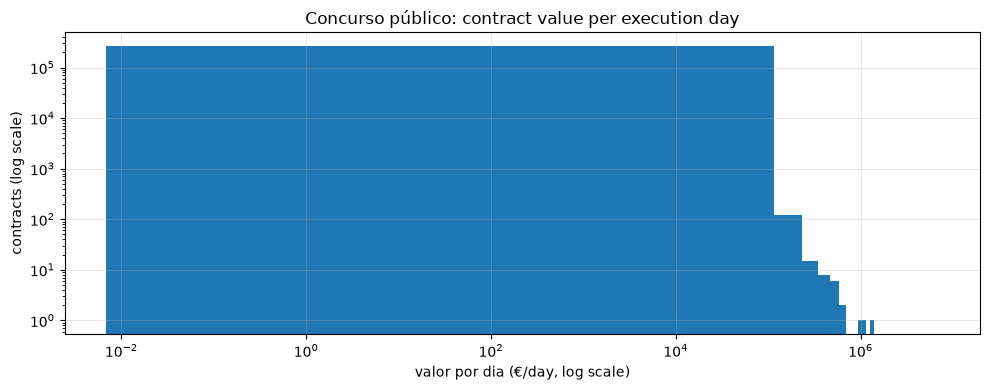

In [6]:
# Execution time (prazo_execucao, days) and value per day. valor_por_dia is null outside 1..3650 days.
d = proc
print(f"prazo_execucao outside 1..3650 days (excluded from value/day): {d['valor_por_dia'].is_null().sum():,} of {d.height:,}")
display(d.select(
    *[pl.col("prazo_execucao").quantile(q).alias(f"prazo_p{int(q * 100)}") for q in (0.1, 0.25, 0.5, 0.75, 0.9)],
    *[pl.col("valor_por_dia").quantile(q).round(2).alias(f"eur_dia_p{int(q * 100)}") for q in (0.1, 0.25, 0.5, 0.75, 0.9)],
))
vd = d["valor_por_dia"].drop_nulls()
fig, ax = plt.subplots()
ax.hist(vd.filter(vd > 0).to_numpy(), bins=60, log=True)
ax.set_xscale("log")
ax.set_xlabel("valor por dia (€/day, log scale)")
ax.set_ylabel("contracts (log scale)")
ax.set_title("Concurso público: contract value per execution day")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
# By duration bucket: how price and price/day move with the contract length.
buckets = (
    proc.filter(pl.col("valor_por_dia").is_not_null())
    .with_columns(
        pl.when(pl.col("prazo_execucao") <= 30).then(pl.lit("1-30 d"))
        .when(pl.col("prazo_execucao") <= 90).then(pl.lit("31-90 d"))
        .when(pl.col("prazo_execucao") <= 365).then(pl.lit("91-365 d"))
        .otherwise(pl.lit("366-3650 d")).alias("duracao")
    )
    .group_by("duracao")
    .agg(
        pl.len().alias("n_contracts"),
        pl.col("preco_contratual").median().alias("median_value"),
        pl.col("valor_por_dia").median().round(2).alias("median_eur_per_day"),
        pl.col("preco_contratual").sum().round(0).alias("total_value"),
    )
    .sort("median_value")
)
buckets

duracao,n_contracts,median_value,median_eur_per_day,total_value
str,u32,f64,f64,f64
"""1-30 d""",24211,22770.0,1152.15,1.5525e9
"""31-90 d""",37801,52932.74,812.2,4.2004e9
"""91-365 d""",131525,54400.0,217.25,2.6067e10
"""366-3650 d""",72366,81900.0,96.23,4.2140e10


In [8]:
# One row per (contract, awardee), keyed by NIPC; name similarity only for the "-" (no NIF) sentinel.
awardees = entity_key(explode_entities(proc, "adjudicatarios", prefix="adjudicatarios"), prefix="adjudicatarios")
print(awardees["adjudicatarios_status"].value_counts(sort=True))
print(awardees["adjudicatarios_key_source"].value_counts(sort=True))

shape: (2, 2)
┌───────────────────────┬────────┐
│ adjudicatarios_status ┆ count  │
│ ---                   ┆ ---    │
│ str                   ┆ u32    │
╞═══════════════════════╪════════╡
│ YES                   ┆ 267358 │
│ NO_NIF                ┆ 7630   │
└───────────────────────┴────────┘
shape: (2, 2)
┌───────────────────────────┬────────┐
│ adjudicatarios_key_source ┆ count  │
│ ---                       ┆ ---    │
│ str                       ┆ u32    │
╞═══════════════════════════╪════════╡
│ nipc                      ┆ 267358 │
│ name                      ┆ 7630   │
└───────────────────────────┴────────┘


In [9]:
by_adjudicante = (
    proc.group_by("adjudicante_key")
    .agg(pl.len().alias("n_contracts"), pl.col("preco_contratual").sum().round(2).alias("total_value"))
    .join(canonical_names(proc, prefix="adjudicante"), on="adjudicante_key", how="left")
)
print("Top 20 adjudicantes by Concurso público count:")
display(by_adjudicante.sort("n_contracts", descending=True).head(20))
print("\nTop 20 adjudicantes by Concurso público value:")
display(by_adjudicante.sort("total_value", descending=True).head(20))

Top 20 adjudicantes by Concurso público count:


adjudicante_key,n_contracts,total_value,adjudicante_name
str,u32,f64,str
"""508080142""",8190,6.2219e8,"""Unidade Local de Saúde de São …"
"""500745471""",5589,1.0985e9,"""Santa Casa da Misericórdia de …"
"""510745997""",3934,2.8339e8,"""Unidade Local de Saúde do Alga…"
"""508481287""",3923,3.5144e8,"""Unidade Local de Saúde de Sant…"
"""509186998""",3421,1.3286e8,"""Unidade Local de Saúde do Arco…"
"""600012662""",3244,2.6974e8,"""MARINHA - Direção de Abastecim…"
"""511228848""",3055,3.4678e8,"""Serviço de Saúde da Região Aut…"
"""500051062""",2997,6.6057e8,"""Município de Sintra"""
"""503933813""",2875,7.1345e9,"""Infraestruturas de Portugal, S…"



Top 20 adjudicantes by Concurso público value:


adjudicante_key,n_contracts,total_value,adjudicante_name
str,u32,f64,str
"""503933813""",2875,7.1345e9,"""Infraestruturas de Portugal, S…"
"""516150359""",48,1.2228e9,"""TML - Transportes Metropolitan…"
"""500051070""",1441,1.1928e9,"""Município de Lisboa"""
"""503278602""",48,1.1156e9,"""Metro do Porto, SA"""
"""500745471""",5589,1.0985e9,"""Santa Casa da Misericórdia de …"
"""600010686""",1425,8.3807e8,"""Estado Maior da Força Aérea"""
"""503450189""",506,7.3623e8,"""Edia - Empresa de Desenvolvime…"
"""500192855""",245,7.3074e8,"""Metropolitano de Lisboa, EPE"""
"""500745943""",1920,7.1685e8,"""Município de Oeiras"""


In [10]:
# One row per (contract, awardee). Contract value is not split between awardees: for multi-awardee
# contracts the value is counted in full for each awardee (state this when reading the table).
awardees = awardees.join(proc.select("idcontrato", "preco_contratual"), on="idcontrato", how="left")
by_awardee = (
    awardees.group_by("adjudicatarios_key")
    .agg(
        pl.len().alias("n_contracts"),
        pl.col("preco_contratual").sum().round(2).alias("total_value"),
        pl.col("adjudicatarios_key_source").first().alias("key_source"),
    )
    .join(canonical_names(awardees, prefix="adjudicatarios"), on="adjudicatarios_key", how="left")
)
print("Top 20 adjudicatarios by count (key_source 'name' = similarity-clustered, no NIF):")
display(by_awardee.sort("n_contracts", descending=True).head(20))
print("\nTop 20 adjudicatarios by value:")
display(by_awardee.sort("total_value", descending=True).head(20))
n_name = awardees.filter(pl.col("adjudicatarios_key_source") == "name").height
print(f"awardee entries keyed by name fallback: {n_name:,} of {awardees.height:,} ({n_name / awardees.height:.1%})")

Top 20 adjudicatarios by count (key_source 'name' = similarity-clustered, no NIF):


adjudicatarios_key,n_contracts,total_value,key_source,adjudicatarios_name
str,u32,f64,str,str
"""504615947""",2351,8.7136e8,"""nipc""","""MEO - Serviços de Comunicações…"
"""504223933""",2233,2.7131e8,"""nipc""","""MEDTRONIC PORTUGAL, LDA."""
"""501506543""",2174,7.9557e7,"""nipc""","""B.Braun Medical, Unipessoal Ld…"
"""500271518""",1440,1.4038e8,"""nipc""","""Sogenave - Sociedade Geral de …"
"""500697370""",1421,5.9885e8,"""nipc""","""Petrogal, S.A."""
"""500153370""",1252,1.7411e8,"""nipc""","""JOHNSON & JOHNSON, LDA"""
"""500684324""",1182,9.3250e7,"""nipc""","""MEDICINÁLIA CORMÉDICA - MCMEDI…"
"""500918880""",1120,3.5791e8,"""nipc""","""Fidelidade – Companhia de Segu…"
"""510533515""",1091,2.2130818e7,"""nipc""","""Medline international Portugal…"



Top 20 adjudicatarios by value:


adjudicatarios_key,n_contracts,total_value,key_source,adjudicatarios_name
str,u32,f64,str,str
"""518400581""",1,1.6614e9,"""nipc""","""AVAN Norte – Gestão da Ferrovi…"
"""501489126""",224,1.0124e9,"""nipc""","""Domingos da Silva teixeira, S.…"
"""501312412""",88,9.9736e8,"""nipc""","""Alberto Couto Alves, S.A."""
"""501323325""",681,9.0221e8,"""nipc""","""Uniself - Sociedade de Restaur…"
"""504615947""",2351,8.7136e8,"""nipc""","""MEO - Serviços de Comunicações…"
"""500197814""",140,8.3854e8,"""nipc""","""Mota-Engil - Engenharia e Cons…"
"""500553408""",268,7.6098e8,"""nipc""","""Alexandre Barbosa Borges, S.A."""
"""503504564""",773,7.3076e8,"""nipc""","""EDP Comercial - Comercializaçã…"
"""500126623""",644,6.8954e8,"""nipc""","""Gertal - Companhia Geral de Re…"


awardee entries keyed by name fallback: 7,630 of 274,988 (2.8%)


In [11]:
# Effect of NIPC-first keying: entity rows the old (nipc, name) grouping produced vs the key grouping.
old = proc.group_by("adjudicante_key", "adjudicante_name").len()
new = proc.group_by("adjudicante_key").len()
print(f"adjudicante rows: {old.height:,} (key, name spelling) -> {new.height:,} keys")
old_a = awardees.group_by("adjudicatarios_key", "adjudicatarios_name").len()
print(f"adjudicatario rows: {old_a.height:,} (key, name) -> {awardees['adjudicatarios_key'].n_unique():,} keys")
biggest = (
    proc.group_by("adjudicante_key")
    .agg(pl.col("adjudicante_name").n_unique().alias("n_spellings"), pl.len().alias("n_contracts"))
    .sort("n_spellings", descending=True)
    .head(5)
)
display(biggest)

adjudicante rows: 3,710 (key, name spelling) -> 3,709 keys
adjudicatario rows: 65,781 (key, name) -> 18,656 keys


adjudicante_key,n_spellings,n_contracts
str,u32,u32
"""503537624""",2,11
"""672000830""",1,20
"""501130179""",1,1
"""502459336""",1,1
"""509186998""",1,3421


shape: (9, 2)
┌────────────┬───────────────┐
│ statistic  ┆ value         │
│ ---        ┆ ---           │
│ str        ┆ f64           │
╞════════════╪═══════════════╡
│ count      ┆ 267117.0      │
│ null_count ┆ 0.0           │
│ mean       ┆ 288090.332675 │
│ std        ┆ 3.9975e6      │
│ min        ┆ -1.0566e7     │
│ 25%        ┆ 12168.0       │
│ 50%        ┆ 55798.08      │
│ 75%        ┆ 168311.13     │
│ max        ┆ 1.6614e9      │
└────────────┴───────────────┘


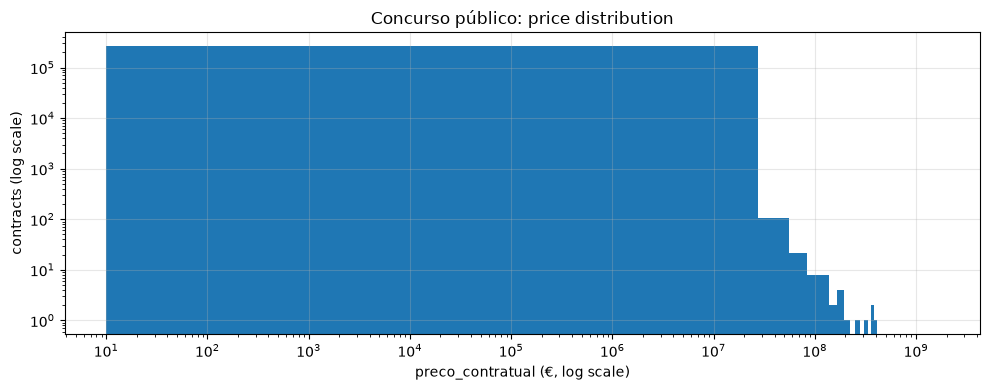

contracts above €5,000: 224,886
contracts above €20,000: 181,637
contracts above €75,000: 116,072


In [12]:
prices = proc["preco_contratual"].drop_nulls()
print(prices.describe())
fig, ax = plt.subplots()
ax.hist(prices.filter(prices > 0).to_numpy(), bins=60, log=True)
ax.set_xscale("log")
ax.set_xlabel("preco_contratual (€, log scale)")
ax.set_ylabel("contracts (log scale)")
ax.set_title("Concurso público: price distribution")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
# Informal reference points only, not legal advice.
for t in (5_000, 20_000, 75_000):
    print(f"contracts above €{t:,}: {(prices > t).sum():,}")

concorrentes reported: 73.7%
shape: (9, 2)
┌────────────┬──────────┐
│ statistic  ┆ value    │
│ ---        ┆ ---      │
│ str        ┆ f64      │
╞════════════╪══════════╡
│ count      ┆ 196868.0 │
│ null_count ┆ 0.0      │
│ mean       ┆ 7.253281 │
│ std        ┆ 7.058125 │
│ min        ┆ 1.0      │
│ 25%        ┆ 3.0      │
│ 50%        ┆ 5.0      │
│ 75%        ┆ 9.0      │
│ max        ┆ 161.0    │
└────────────┴──────────┘


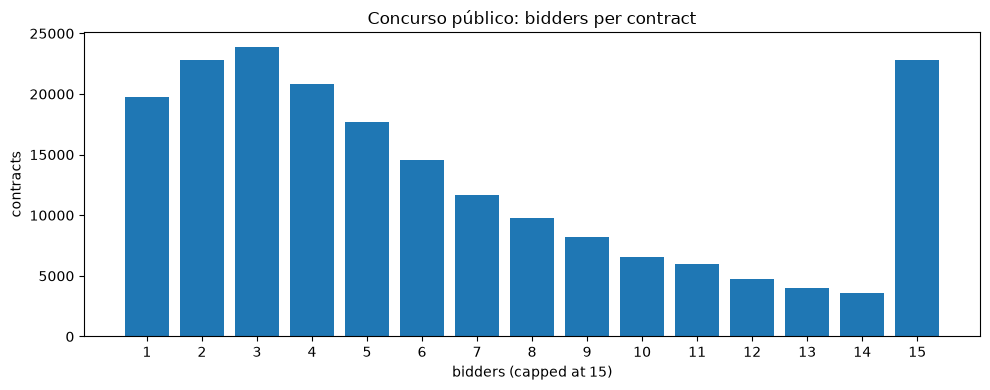

Single-bidder share among reported: 10.0%


In [13]:
# Competition: `concorrentes` is a "\n"-separated list of "NIPC-name" bidders (null = not reported).
proc = proc.with_columns(
    pl.col("concorrentes").str.split("\n").list.eval(pl.element().str.strip_chars().filter(pl.element() != "")).list.len().alias("n_concorrentes")
)
print(f"concorrentes reported: {proc['concorrentes'].is_not_null().mean():.1%}")
print(proc["n_concorrentes"].drop_nulls().describe())
fig, ax = plt.subplots()
counts = proc["n_concorrentes"].drop_nulls().clip(upper_bound=15).value_counts().sort("n_concorrentes")
ax.bar(counts["n_concorrentes"].cast(pl.String), counts["count"])
ax.set_xlabel("bidders (capped at 15)")
ax.set_ylabel("contracts")
ax.set_title("Concurso público: bidders per contract")
plt.tight_layout()
plt.show()
print("Single-bidder share among reported:", f"{(proc['n_concorrentes'] == 1).sum() / proc['n_concorrentes'].drop_nulls().len():.1%}")

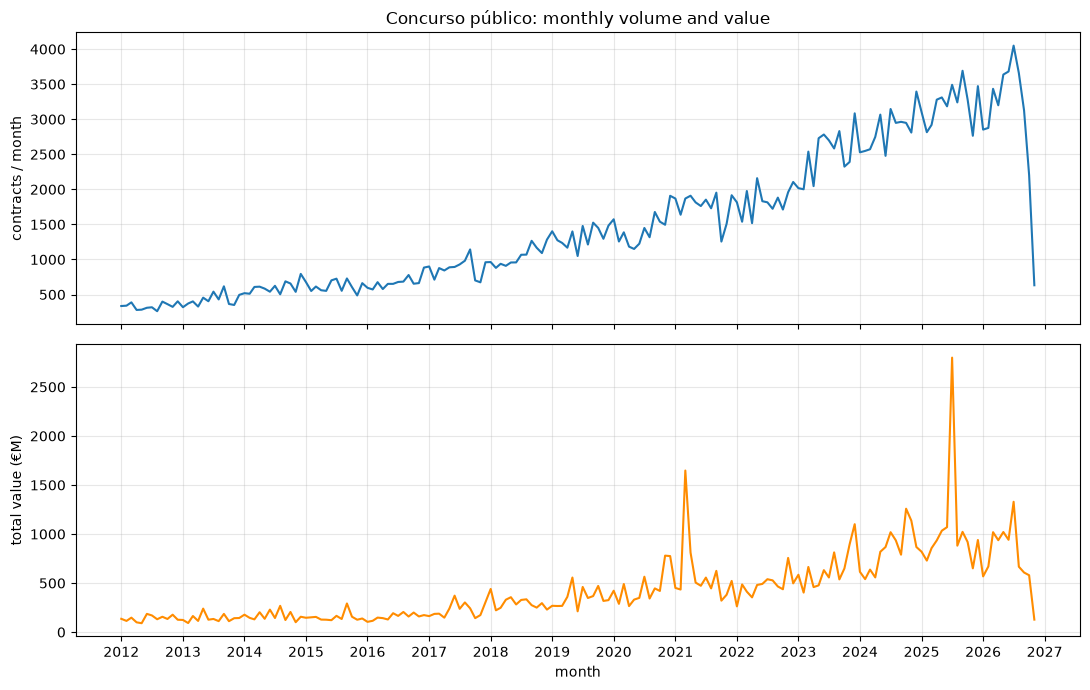

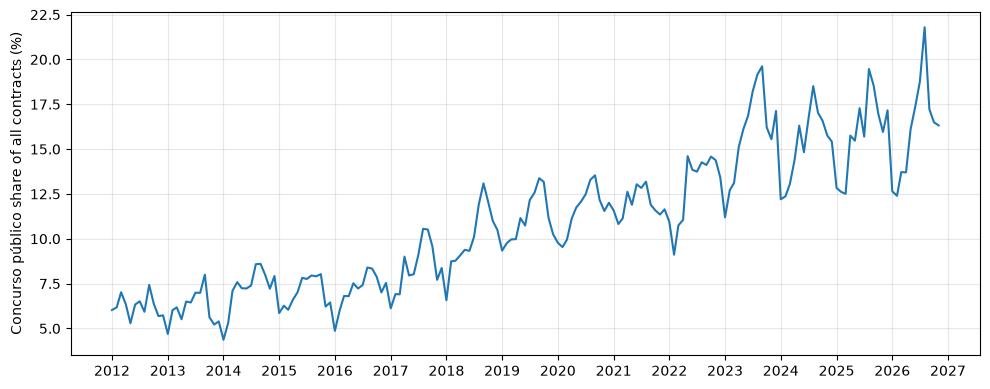

In [14]:
concurso_publico_monthly = (
    contracts.filter(pl.col("data_celebracao").is_not_null())
    .with_columns(pl.col("data_celebracao").dt.truncate("1mo").alias("month"))
    .group_by("month")
    .agg(
        pl.len().alias("n_all"),
        CP_EXPR.sum().alias("n_contracts"),
        pl.col("preco_contratual").filter(CP_EXPR).sum().alias("total_value"),
    )
    .with_columns((pl.col("n_contracts") / pl.col("n_all")).alias("share"))
    .sort("month")
)
monthly = concurso_publico_monthly
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(monthly["month"], monthly["n_contracts"])
axes[0].set_ylabel("contracts / month")
axes[0].set_title("Concurso público: monthly volume and value")
axes[1].plot(monthly["month"], monthly["total_value"] / 1e6, color="darkorange")
axes[1].set_ylabel("total value (€M)")
axes[1].set_xlabel("month")
for ax in axes:
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots()
ax.plot(concurso_publico_monthly["month"], concurso_publico_monthly["share"] * 100)
ax.set_ylabel("Concurso público share of all contracts (%)")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
proc.sort("preco_contratual", descending=True, nulls_last=True).select(
    "idcontrato", "adjudicante_name", "preco_contratual", "tipo_procedimento", "data_celebracao", "objecto_contrato"
).head(10)

idcontrato,adjudicante_name,preco_contratual,tipo_procedimento,data_celebracao,objecto_contrato
i64,str,f64,str,date,str
11724697,"""Infraestruturas de Portugal, S…",1.6614e9,"""Concurso público""",2025-07-29,"""Concurso Público com Publicida…"
7392833,"""TML - Transportes Metropolitan…",3.9719e8,"""Concurso público""",2021-03-24,"""Aquisição do Serviço Público d…"
10394037,"""Metro do Porto, SA""",3.795e8,"""Concurso público""",2023-11-03,"""CONCURSO PÚBLICO PARA A EMPREI…"
7392892,"""TML - Transportes Metropolitan…",3.6458e8,"""Concurso público""",2021-03-24,"""Aquisição do Serviço Público d…"
10585414,"""Metropolitano de Lisboa, EPE""",3.21888e8,"""Concurso público""",2023-12-22,"""Empreitada de Conceção e Const…"
7392896,"""TML - Transportes Metropolitan…",2.5917e8,"""Concurso público""",2021-03-24,"""Aquisição do Serviço Público d…"
11293048,"""Metro do Porto, SA""",2.0434e8,"""Concurso público""",2018-01-11,"""Subconcessão do Sistema de Met…"
7626845,"""Metro do Porto, SA""",1.8906e8,"""Concurso público""",2020-11-25,"""Concurso Público para a Emprei…"
7392921,"""TML - Transportes Metropolitan…",1.8471e8,"""Concurso público""",2021-03-24,"""Aquisição do Serviço Público d…"


## Commentary and limitations

- `Ano` covers 2012–2026 (data up to 2026-11-14); edge months of the monthly series are partial.
- Awardee value totals count a multi-awardee contract in full for each awardee.
- Entities are keyed by NIPC. Entries with the `-` (no NIF) sentinel are clustered by name similarity
  (`token_sort_ratio >= 92`) and may over- or under-merge; see `key_source`. Dirty NIPCs stay separate keys.
- Very large values may be outliers or data-entry errors.
- `concorrentes` is missing for many contracts; bidder statistics use reported values only.
- Contracts with |value| below €10 (`MIN_VALUE`, applied to the absolute value) are disregarded; the before/after cell quantifies the effect.
- `valor_por_dia` = `preco_contratual / prazo_execucao`, only for 1–3650 days (0-day and >10-year values are treated as data errors). Short contracts inflate €/day.